# Candy concept analysis for Lidl

Lidl wants a new store-brand candy, and the team is debating options such as a biscuit-based sweet or gummies. I look for the
characteristics that drive preference and then for the recipe the data supports best. I'd prototype a chocolate bar with a crispy
layer: it is among the top recipes that real products support and scores 21 percentage points above the fruit-flavoured comparison group.

FiveThirtyEight's *Candy Power Ranking* (CC BY 4.0) recorded about 269,000 pairwise choices across 85 entries. Each product's
`winpercent` is the share of its own match-ups that it won. One limitation matters for this decision: all seven crispy products
contain chocolate, so the survey says little about how a plain biscuit would do.

Only this file is used, and the models are written with numpy and scipy.

## 1. The dataset

* `chocolate`, `fruity`, `caramel`, `peanutyalmondy`, `nougat`: does the candy contain it? (1 = yes)
* `crispedricewafer`: crisped rice, wafer or a cookie component
* `hard`: hard candy · `bar`: a candy bar · `pluribus`: one of many candies in a bag or box
* `sugarpercent`, `pricepercent`: sugar and unit-price percentile within the data set
* `winpercent`: share of head-to-head match-ups won (the outcome)

In [1]:
import os
from itertools import permutations, product
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats
from scipy.special import expit

SEED = 2024
pd.set_option('display.precision', 2)
pd.set_option('display.max_colwidth', 90)
os.makedirs('outputs', exist_ok=True)

In [2]:
raw = pd.read_csv('candy-data.csv')

In [3]:
raw.head()

,competitorname,chocolate,fruity,caramel,peanutyalmondy,nougat,crispedricewafer,hard,bar,pluribus,sugarpercent,pricepercent,winpercent
0,100 Grand,1,0,1,0,0,1,0,1,0,0.73,0.86,66.97
1,3 Musketeers,1,0,0,0,1,0,0,1,0,0.60,0.51,67.60
2,One dime,0,0,0,0,0,0,0,0,0,0.01,0.12,32.26
3,One quarter,0,0,0,0,0,0,0,0,0,0.01,0.51,46.12
4,Air Heads,0,1,0,0,0,0,0,0,0,0.91,0.51,52.34


In [4]:
raw.shape

(85, 13)

In [5]:
raw.info()

<class 'pandas.DataFrame'>
RangeIndex: 85 entries, 0 to 84
Data columns (total 13 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   competitorname    85 non-null     str    
 1   chocolate         85 non-null     int64  
 2   fruity            85 non-null     int64  
 3   caramel           85 non-null     int64  
 4   peanutyalmondy    85 non-null     int64  
 5   nougat            85 non-null     int64  
 6   crispedricewafer  85 non-null     int64  
 7   hard              85 non-null     int64  
 8   bar               85 non-null     int64  
 9   pluribus          85 non-null     int64  
 10  sugarpercent      85 non-null     float64
 11  pricepercent      85 non-null     float64
 12  winpercent        85 non-null     float64
dtypes: float64(3), int64(9), str(1)
memory usage: 8.8 KB


In [6]:
raw[raw.competitorname.isin(['One dime', 'One quarter'])]

,competitorname,chocolate,fruity,caramel,peanutyalmondy,nougat,crispedricewafer,hard,bar,pluribus,sugarpercent,pricepercent,winpercent
2,One dime,0,0,0,0,0,0,0,0,0,0.01,0.12,32.26
3,One quarter,0,0,0,0,0,0,0,0,0,0.01,0.51,46.12


The file contains 85 entries and no missing values. I excluded *One dime* and *One quarter*: they are coins (every characteristic is 0),
and Lidl is choosing a candy to develop; section 8 shows that keeping them changes nothing. I also merged `bar` and `pluribus`,
which are never both 1, into one `form` column (bar = +1, multi-piece = −1, neither = 0). This leaves 83 products.

In [7]:
df = raw[~raw.competitorname.isin(['One dime', 'One quarter'])].reset_index(drop=True)
df['form'] = df.bar - df.pluribus
df.shape

(83, 14)

## 2. Exploring the data

How often does each characteristic occur?

In [8]:
flags = ['chocolate', 'fruity', 'caramel', 'peanutyalmondy', 'nougat', 'crispedricewafer', 'hard', 'bar', 'pluribus']

def count(feature, ax):
    n = df[feature].value_counts().reindex([0, 1], fill_value=0)
    ax.bar(['no', 'yes'], n.values, color=['#c3c2bd', '#2a78d6'])
    ax.set_title(feature)

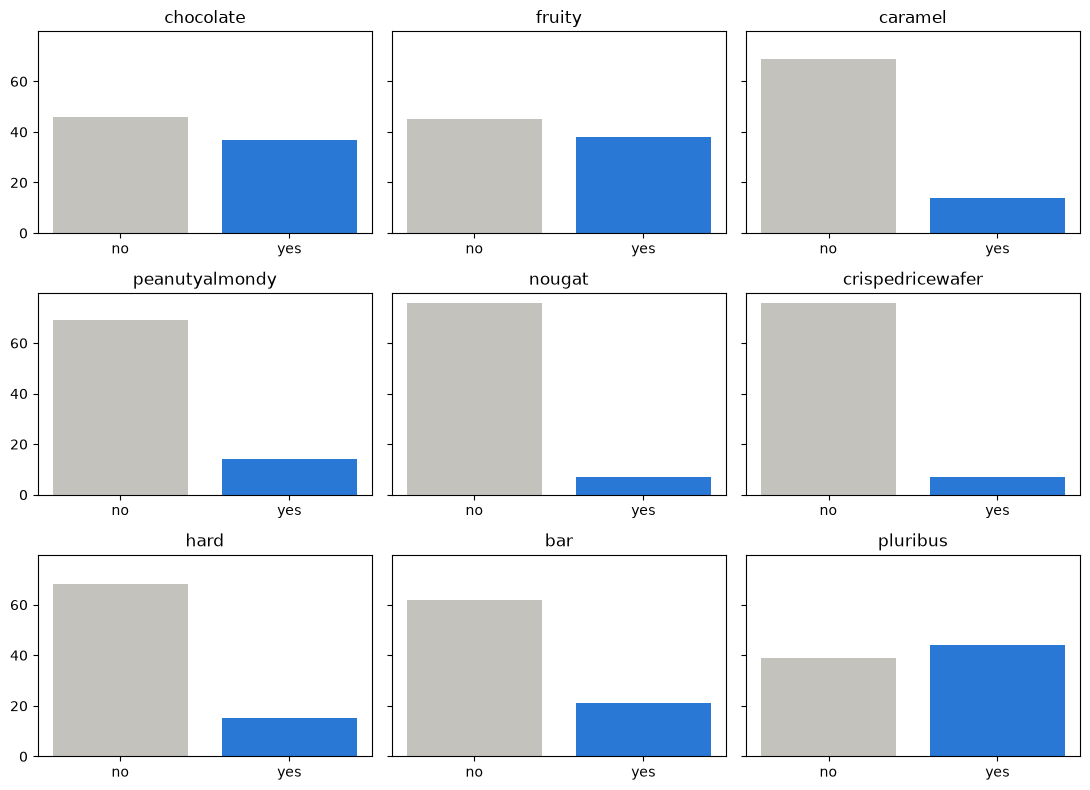

In [9]:
fig, axes = plt.subplots(3, 3, figsize=(11, 8), sharey=True)
for f, ax in zip(flags, axes.flat):
    count(f, ax)
plt.tight_layout()

Chocolate (37) and fruit flavour (38) are common; nougat and crispy are rare (7 each), so their effects rest on few products.
Multi-piece candies (44) outnumber bars (21).

How are the win rates distributed?

In [10]:
df.winpercent.describe()

count    83.00
mean     50.58
std      14.75
min      22.45
25%      39.16
50%      48.98
75%      60.33
max      84.18
Name: winpercent, dtype: float64

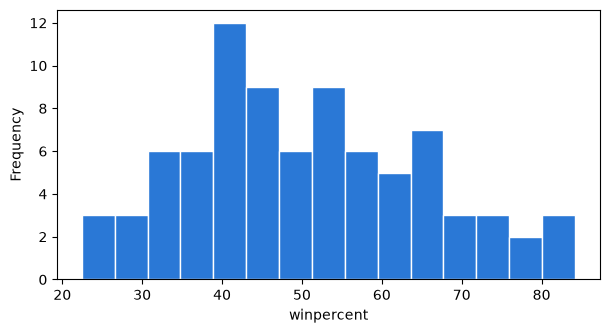

In [11]:
df.winpercent.plot.hist(bins=15, color='#2a78d6', edgecolor='white', figsize=(7, 3.5))
plt.xlabel('winpercent');

From 22% to 84%, roughly symmetric and without extreme values, so averages and a linear model are a reasonable start.

In [12]:
df.nlargest(10, 'winpercent')[['competitorname', 'chocolate', 'peanutyalmondy', 'crispedricewafer', 'bar', 'winpercent']]

,competitorname,chocolate,peanutyalmondy,crispedricewafer,bar,winpercent
50,Reese's Peanut Butter cup,1,1,0,0,84.18
49,Reese's Miniatures,1,1,0,0,81.87
77,Twix,1,0,1,1,81.64
26,Kit Kat,1,0,1,1,76.77
62,Snickers,1,1,0,1,76.67
51,Reese's pieces,1,1,0,0,73.43
34,Milky Way,1,0,0,1,73.10
52,Reese's stuffed with pieces,1,1,0,0,72.89
30,Peanut butter M&M's,1,1,0,0,71.47
40,Nestle Butterfinger,1,1,0,1,70.74


All ten winners contain chocolate, seven also peanut (four are Reese's). The crispy bars Twix and Kit Kat rank 3rd and 4th.

In [13]:
df.nsmallest(10, 'winpercent')[['competitorname', 'chocolate', 'fruity', 'hard', 'pluribus', 'winpercent']]

,competitorname,chocolate,fruity,hard,pluribus,winpercent
42,Nik L Nip,0,1,0,1,22.45
5,Boston Baked Beans,0,0,0,1,23.42
10,Chiclets,0,1,0,1,24.52
70,Super Bubble,0,1,0,0,27.30
24,Jawbusters,0,1,1,1,28.13
55,Root Beer Barrels,0,0,1,1,29.70
69,Sugar Daddy,0,0,0,0,32.23
68,Sugar Babies,0,0,0,1,33.44
17,Haribo Happy Cola,0,0,0,1,34.16
7,Caramel Apple Pops,0,1,0,0,34.52


None of the ten weakest contains chocolate; seven are multi-piece and five fruit-flavoured.

In [14]:
def box(feature, ax):
    ax.boxplot([df.loc[df[feature] == v, 'winpercent'] for v in (0, 1)], tick_labels=['no', 'yes'])
    ax.set_title(feature)

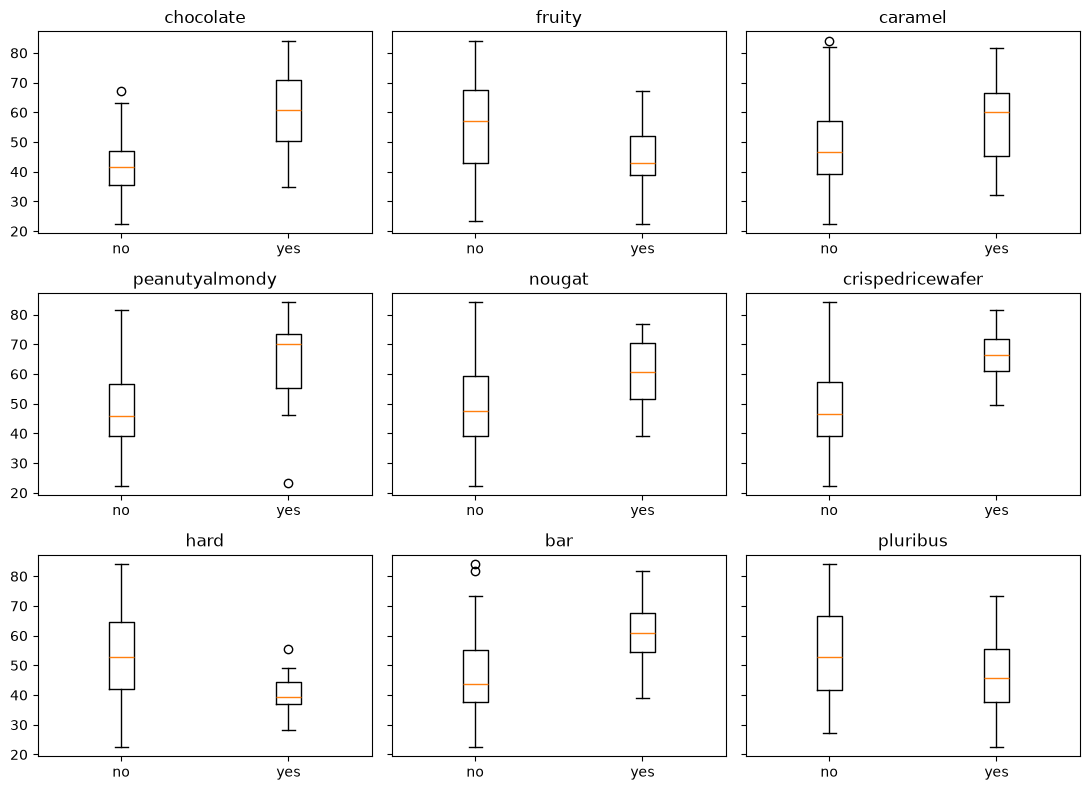

In [15]:
fig, axes = plt.subplots(3, 3, figsize=(11, 8), sharey=True)
for f, ax in zip(flags, axes.flat):
    box(f, ax)
plt.tight_layout()

Chocolate, peanut, crispy and bar candies have higher medians (61–70% against 42–47% without); fruit, hard and multi-piece candies lower.
These raw differences overlap, which is what the models separate.

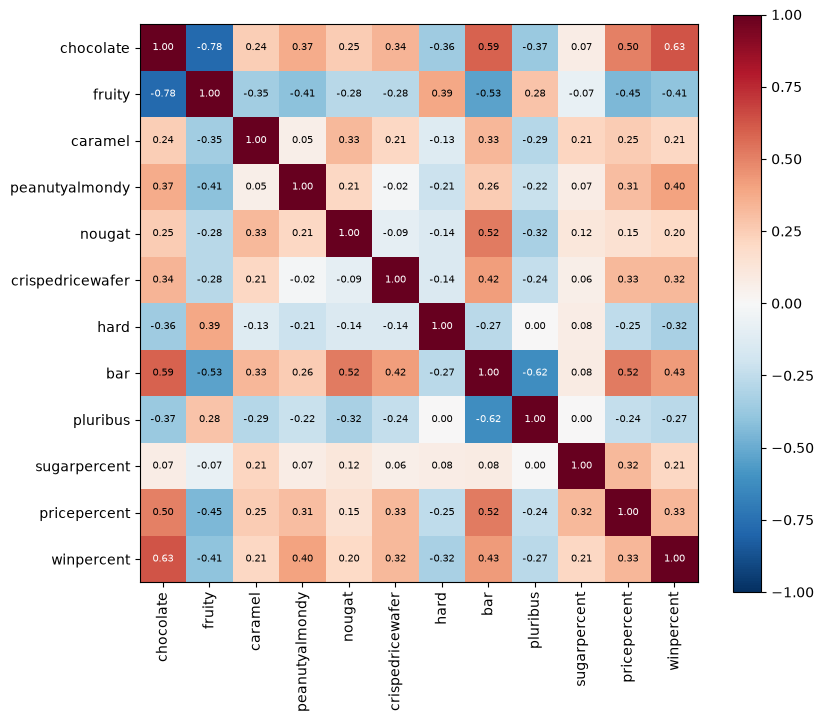

In [16]:
cols = flags + ['sugarpercent', 'pricepercent', 'winpercent']
corr = df[cols].corr()
fig, ax = plt.subplots(figsize=(9, 7.5))
im = ax.imshow(corr, cmap='RdBu_r', vmin=-1, vmax=1)
ax.set_xticks(range(len(cols)), cols, rotation=90)
ax.set_yticks(range(len(cols)), cols)
for i in range(len(cols)):
    for j in range(len(cols)):
        ax.text(j, i, f'{corr.iloc[i, j]:.2f}', ha='center', va='center', fontsize=7,
                color='white' if abs(corr.iloc[i, j]) > .6 else 'black')
fig.colorbar(im);

Chocolate correlates most with `winpercent` (0.63). Chocolate and fruit almost exclude each other (−0.78), bar and multi-piece are
opposites (−0.62), and chocolate candies are pricier (0.50).

## 3. Comparing groups of real products

Differences in mean `winpercent` with Welch 95% confidence intervals. No model involved.

In [17]:
def welch(a, b):
    t = stats.ttest_ind(a, b, equal_var=False)
    ci = t.confidence_interval()
    return pd.Series({'n a': len(a), 'n b': len(b), 'mean a': a.mean(), 'mean b': b.mean(),
                      'difference': a.mean() - b.mean(), 'ci low': ci.low, 'ci high': ci.high, 'p': t.pvalue})

In [18]:
w = df.winpercent
choc, bar, crispy, nut = (df[c] == 1 for c in ['chocolate', 'bar', 'crispedricewafer', 'peanutyalmondy'])
others = ['chocolate', 'caramel', 'peanutyalmondy', 'nougat', 'crispedricewafer', 'hard', 'bar']
fruit_multi = (df.fruity == 1) & (df.pluribus == 1) & (df[others].sum(axis=1) == 0)

In [19]:
crispy_products = df.assign(rank=w.rank(ascending=False).astype(int))[crispy]
crispy_products[['competitorname', 'chocolate', 'bar', 'caramel', 'peanutyalmondy', 'winpercent', 'rank']]

,competitorname,chocolate,bar,caramel,peanutyalmondy,winpercent,rank
0,100 Grand,1,1,1,0,66.97,14
21,Hershey's Krackel,1,1,0,0,62.28,20
26,Kit Kat,1,1,0,0,76.77,4
41,Nestle Crunch,1,1,0,0,66.47,16
63,Snickers Crisper,1,1,1,1,59.53,23
77,Twix,1,1,1,0,81.64,3
82,Whoppers,1,0,0,0,49.52,41


All 7 crispy products contain chocolate, so the data cannot score a crispy candy without chocolate, such as a plain biscuit.
The flag does not say whether the crispy part is rice, wafer or cookie.

The data has no gummy flag. I used fruit-flavoured, multi-piece sweets with no other characteristic as a proxy for gummies:

In [20]:
df[fruit_multi][['competitorname', 'winpercent']].sort_values('winpercent', ascending=False)

,competitorname,winpercent
66,Starburst,67.04
58,Skittles original,63.09
64,Sour Patch Kids,59.86
16,Haribo Gold Bears,57.12
59,Skittles wildberry,55.10
71,Swedish Fish,54.86
65,Sour Patch Tricksters,52.83
18,Haribo Sour Bears,51.41
76,Trolli Sour Bites,47.17
32,Mike & Ike,46.41


The 19 candies average 47%. The rule includes Skittles and misses Haribo Happy Cola (not flagged as fruit), so I'd test the prototype
against an actual fruit gummy.

In [21]:
groups = pd.DataFrame({
    'chocolate vs no chocolate': welch(w[choc], w[~choc]),
    'crispy chocolate bars vs fruit multi-piece': welch(w[choc & crispy & bar], w[fruit_multi]),
    'within chocolate: crispy vs not': welch(w[choc & crispy], w[choc & ~crispy]),
    'within chocolate: peanut vs not': welch(w[choc & nut], w[choc & ~nut]),
    'within chocolate bars: peanut vs not': welch(w[choc & bar & nut], w[choc & bar & ~nut]),
    'within chocolate, not bars: peanut vs not': welch(w[choc & ~bar & nut], w[choc & ~bar & ~nut]),
}).T
groups

,n a,n b,mean a,mean b,difference,ci low,ci high,p
chocolate vs no chocolate,37.0,46.0,60.92,42.27,18.65,13.47,23.84,6.57e-10
crispy chocolate bars vs fruit multi-piece,6.0,19.0,68.94,46.66,22.28,12.60,31.96,3.13e-04
within chocolate: crispy vs not,7.0,30.0,66.17,59.70,6.47,-3.92,16.87,1.97e-01
within chocolate: peanut vs not,12.0,25.0,68.50,57.28,11.22,3.04,19.41,9.24e-03
within chocolate bars: peanut vs not,6.0,14.0,61.45,62.30,-0.84,-12.22,10.54,8.73e-01
"within chocolate, not bars: peanut vs not",6.0,11.0,75.55,50.90,24.66,16.21,33.10,1.70e-05


Chocolate candies win 18.7 points more than the rest, and the 6 crispy chocolate bars beat the fruit multi-piece candies by 22.3 points (95% CI 12.6 to 32.0). Peanut is the interesting case: among chocolate bars it adds nothing (−0.8), while among cups and pieces (Reese's, peanut M&M's) it adds 24.7 points (95% CI 16.2 to 33.1).

## 4. Two models

* **Ridge regression**: linear, so every effect reads directly in percentage points; the penalty `lam` shrinks the 10 coefficients,
  which keeps them stable on 83 products.
* **Fractional logit**: `winpercent` is a share, so the prediction is kept between 0 and 100; same penalty idea.

`lam` is chosen by 5 × 3-fold cross-validation.

Both models get one interaction, **peanut × bar**. Section 3 shows that peanut adds a lot to cups and pieces
but nothing to bars, and a purely additive model would carry the cup effect over to a peanut bar. I added this term after a first
version without it scored the peanut bar above the crispy bar, against the real bars; section 5 checks it out of sample.

In [22]:
features = ['chocolate', 'fruity', 'caramel', 'peanutyalmondy', 'nougat', 'crispedricewafer', 'hard',
            'sugarpercent', 'pricepercent', 'form']
X, y = df[features].to_numpy(float), w.to_numpy()

In [23]:
def expand(X, interaction=True):
    peanut_bar = X[:, features.index('peanutyalmondy')] * (X[:, features.index('form')] == 1)
    return np.c_[X, peanut_bar] if interaction else X


def ridge(X, y, lam, interaction=True):
    Xe = expand(X, interaction)
    mu, sd = Xe.mean(0), np.where(Xe.std(0) > 0, Xe.std(0), 1)
    Z = (Xe - mu) / sd
    b = np.linalg.solve(Z.T @ Z + lam * np.eye(Z.shape[1]), Z.T @ (y - y.mean()))
    return lambda Xn: y.mean() + (expand(Xn, interaction) - mu) / sd @ b


def frac_logit(X, y, lam):
    Xe = expand(X)
    mu, sd = Xe.mean(0), np.where(Xe.std(0) > 0, Xe.std(0), 1)
    Z = np.c_[np.ones(len(y)), (Xe - mu) / sd]
    P = lam * np.diag([0] + [1] * Xe.shape[1])
    b = np.zeros(Z.shape[1])
    for _ in range(25):
        p = expit(Z @ b)
        b += np.linalg.solve(Z.T @ (Z * (p * (1 - p))[:, None]) + P, Z.T @ (y / 100 - p) - P @ b)
    return lambda Xn: 100 * expit(np.c_[np.ones(len(Xn)), (expand(Xn) - mu) / sd] @ b)


ridge_no_interaction = lambda X, y, lam: ridge(X, y, lam, interaction=False)

In [24]:
lams = np.logspace(-2, 3, 11)

def tune(fit, X, y, seed):
    err = np.zeros(len(lams))
    for r in range(5):
        for te in np.array_split(np.random.default_rng(seed + r).permutation(len(y)), 3):
            tr = np.setdiff1d(np.arange(len(y)), te)
            err += [np.abs(fit(X[tr], y[tr], lam)(X[te]) - y[te]).mean() for lam in lams]
    return lams[err.argmin()]

Fit both models on all 83 candies.

In [25]:
lam_ridge = tune(ridge, X, y, SEED)
lam_logit = tune(frac_logit, X, y, SEED)
pd.Series({'ridge': lam_ridge, 'frac. logit': lam_logit})

ridge          3.16
frac. logit    1.00
dtype: float64

Both penalties are small compared with the size of the data, so they shrink the coefficients only slightly.

In [26]:
models = {'ridge': ridge(X, y, lam_ridge),
          'frac. logit': frac_logit(X, y, lam_logit)}

## 5. Out-of-sample accuracy

5 repeats × 5-fold cross-validation: 25 train / test splits, identical for all models. All tuning happens inside the training part.
The baseline predicts the training mean.

In [27]:
rows, fold_ridges = [], []
splits = [s for r in range(5) for s in np.array_split(np.random.default_rng(SEED + r).permutation(len(y)), 5)]
for k, te in enumerate(splits):
    tr = np.setdiff1d(np.arange(len(y)), te)
    ridge_k = ridge(X[tr], y[tr], tune(ridge, X[tr], y[tr], k))
    fold_ridges.append((ridge_k, te))
    preds = {'baseline': np.full(len(te), y[tr].mean()),
             'ridge, no interaction': ridge_no_interaction(X[tr], y[tr], tune(ridge_no_interaction, X[tr], y[tr], k))(X[te]),
             'ridge': ridge_k(X[te]),
             'frac. logit': frac_logit(X[tr], y[tr], tune(frac_logit, X[tr], y[tr], k))(X[te])}
    rows += [{'fold': k, 'model': m, 'MAE': np.abs(p - y[te]).mean(), 'RMSE': np.sqrt(((p - y[te]) ** 2).mean())}
             for m, p in preds.items()]
cv = pd.DataFrame(rows)

In [28]:
accuracy = cv.groupby('model')[['MAE', 'RMSE']].mean().sort_values('MAE')
accuracy

,MAE,RMSE
model,,
frac. logit,9.14,11.36
ridge,9.17,11.39
"ridge, no interaction",9.70,11.78
baseline,12.39,14.70


Both models beat the baseline by about 3.2 points of MAE and are practically tied (9.14 and 9.17). Without the peanut × bar term, ridge is half a point worse (9.70).

How consistent are these differences across the held-out folds? Fold-by-fold MAE differences, with the variance corrected for overlapping training sets (Nadeau–Bengio: × (1/J + n_test / n_train)).

In [29]:
def paired(a, b):
    d = cv[cv.model == a].MAE.to_numpy() - cv[cv.model == b].MAE.to_numpy()
    se = np.sqrt((1 / len(d) + 1 / 4) * d.var(ddof=1))
    q = stats.t.ppf(.975, len(d) - 1)
    return pd.Series({'difference': d.mean(), 'ci low': d.mean() - q * se, 'ci high': d.mean() + q * se,
                      'p': 2 * stats.t.sf(abs(d.mean()) / se, len(d) - 1), 'folds first better': (d < 0).sum()})

comparison = pd.DataFrame({f'{a} − {b}': paired(a, b) for a, b in
                           [('ridge', 'baseline'), ('frac. logit', 'baseline'),
                            ('frac. logit', 'ridge'), ('ridge', 'ridge, no interaction')]}).T
comparison

,difference,ci low,ci high,p,folds first better
ridge − baseline,-3.22,-5.34,-1.10,4.44e-03,24.0
frac. logit − baseline,-3.25,-5.31,-1.19,3.37e-03,24.0
frac. logit − ridge,-0.03,-0.22,0.16,7.72e-01,14.0
"ridge − ridge, no interaction",-0.52,-1.30,0.25,1.75e-01,21.0


Both models beat the baseline (p < 0.005) and cannot be told apart from each other. The peanut × bar term improves ridge in 21 of 25 folds (−0.52 points), but its corrected interval (−1.30 to +0.25) includes 0: the term's main contribution is to the peanut bar's score in section 7, not to average accuracy.

Which characteristics does ridge rely on for new candies? Permutation importance: in every test fold, shuffle one column
(5 times), predict again with that fold's ridge and record how much the MAE rises.

In [30]:
rng = np.random.default_rng(SEED)
perm = np.zeros(len(features))
for ridge_k, te in fold_ridges:
    base = np.abs(ridge_k(X[te]) - y[te]).mean()
    for j in range(len(features)):
        for _ in range(5):
            Xp = X[te].copy()
            Xp[:, j] = rng.permutation(Xp[:, j])
            perm[j] += (np.abs(ridge_k(Xp) - y[te]).mean() - base) / (5 * len(fold_ridges))
importance = pd.Series(perm, index=features).sort_values()

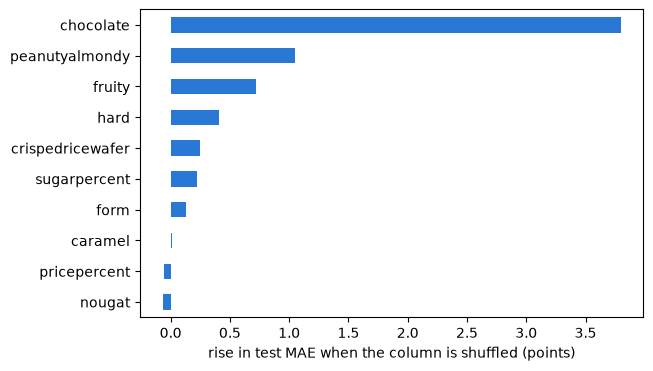

In [31]:
importance.plot.barh(color='#2a78d6', figsize=(6.5, 4))
plt.xlabel('rise in test MAE when the column is shuffled (points)');

Shuffling chocolate raises ridge's test error by 3.8 points; peanut adds 1.0, fruit flavour 0.7 and hard candy 0.4, the rest little or nothing. For new candies, chocolate carries most of the predictive information.

## 6. What drives preference?

Effect of a characteristic: the average change in predicted `winpercent` over the 83 candies when it is switched on
(flags 0 → 1, multi-piece → bar, sugar and price from the 25th to the 75th percentile). The last row swaps fruit flavour for chocolate,
because the two almost never occur together. Intervals: 1,000 bootstrap resamples of the candies, with the penalty held fixed.

In [32]:
q25, q75 = df[['sugarpercent', 'pricepercent']].quantile([.25, .75]).to_numpy()
names = {'chocolate': 'chocolate', 'fruity': 'fruit flavour', 'caramel': 'caramel', 'peanutyalmondy': 'peanut / almond',
         'nougat': 'nougat', 'crispedricewafer': 'crispy', 'hard': 'hard candy'}
changes = {name: {f: (0, 1)} for f, name in names.items()}
changes |= {'peanut / almond, in a bar': {'peanutyalmondy': (0, 1), 'form': (1, 1)},
            'sugar (25th → 75th pct)': {'sugarpercent': (q25[0], q75[0])},
            'price (25th → 75th pct)': {'pricepercent': (q25[1], q75[1])},
            'multi-piece → bar': {'form': (-1, 1)},
            'chocolate instead of fruit': {'chocolate': (0, 1), 'fruity': (1, 0)}}

def effect(predict, change):
    lo, hi = X.copy(), X.copy()
    for f, (a, b) in change.items():
        lo[:, features.index(f)], hi[:, features.index(f)] = a, b
    return (predict(hi) - predict(lo)).mean()

The three candidate concepts, at median sugar and price:

In [33]:
concepts = pd.DataFrame(0.0, index=['A: chocolate crispy bar', 'B: chocolate peanut bar', 'C: fruit multi-piece'], columns=features)
concepts.loc['A: chocolate crispy bar', ['chocolate', 'crispedricewafer', 'form']] = 1
concepts.loc['B: chocolate peanut bar', ['chocolate', 'peanutyalmondy', 'form']] = 1
concepts.loc['C: fruit multi-piece', ['fruity', 'form']] = [1, -1]
concepts[['sugarpercent', 'pricepercent']] = df[['sugarpercent', 'pricepercent']].median().to_numpy()
concepts

,chocolate,fruity,caramel,peanutyalmondy,nougat,crispedricewafer,hard,sugarpercent,pricepercent,form
A: chocolate crispy bar,1.0,0.0,0.0,0.0,0.0,1.0,0.0,0.47,0.47,1.0
B: chocolate peanut bar,1.0,0.0,0.0,1.0,0.0,0.0,0.0,0.47,0.47,1.0
C: fruit multi-piece,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.47,0.47,-1.0


C is the gummy proxy from section 3: fruit-flavoured, multi-piece, nothing else.

Every recipe (characteristics and form) that occurs among the 83 products, also at median sugar and price:

In [34]:
def recipe_name(r):
    parts = [names[f] for f in features[:7] if r[f]] or ['none']
    return ', '.join(parts) + {1: ' · bar', 0: '', -1: ' · multi-piece'}[int(r['form'])]

In [35]:
recipes = df.groupby(features[:7] + ['form']).winpercent.agg(n='size', mean='mean').reset_index()
recipes[['sugarpercent', 'pricepercent']] = concepts[['sugarpercent', 'pricepercent']].iloc[0].to_numpy()
recipes.index = [recipe_name(r) for _, r in recipes.iterrows()]
R = recipes[features].to_numpy()
len(recipes)

28

In [36]:
boot = {'ridge': [], 'frac. logit': []}
for b in range(1000):
    i = np.random.default_rng(SEED + b).integers(0, len(y), len(y))
    for m, fit, lam in [('ridge', ridge, lam_ridge), ('frac. logit', frac_logit, lam_logit)]:
        p = fit(X[i], y[i], lam)
        boot[m].append([effect(p, c) for c in changes.values()] + list(p(concepts.to_numpy())) + list(p(R)))
boot = {m: np.array(v) for m, v in boot.items()}

In [37]:
n_eff = len(changes)
eff = pd.DataFrame({m: [effect(p, c) for c in changes.values()] for m, p in models.items()}, index=list(changes))
eff['ridge low'], eff['ridge high'] = np.percentile(boot['ridge'][:, :n_eff], [2.5, 97.5], axis=0)
eff['logit low'], eff['logit high'] = np.percentile(boot['frac. logit'][:, :n_eff], [2.5, 97.5], axis=0)
eff

,ridge,frac. logit,ridge low,ridge high,logit low,logit high
chocolate,17.52,16.98,9.29e+00,24.69,8.87,23.60
fruit flavour,9.04,8.16,2.65e+00,15.14,1.94,13.28
caramel,2.96,2.82,-3.64e+00,10.23,-3.68,9.89
peanut / almond,12.41,12.36,4.30e+00,20.99,3.82,20.50
nougat,2.78,2.61,-8.54e+00,12.75,-8.35,12.26
crispy,9.21,9.12,2.66e-01,19.86,0.15,19.34
hard candy,-5.74,-5.64,-1.06e+01,-0.63,-10.40,-0.60
"peanut / almond, in a bar",3.17,3.36,-5.38e+00,14.77,-5.09,14.83
sugar (25th → 75th pct),4.03,3.99,-4.68e-04,7.59,-0.02,7.39
price (25th → 75th pct),-2.05,-1.92,-5.74e+00,2.71,-5.39,2.67


In ridge, chocolate adds 17.5 points (95% interval 9.3 to 24.7), crispy 9.2 and fruit flavour 9.0, while hard candy subtracts 5.7. Peanut adds 12.4 on average but only 3.2 in a bar (interval −5.4 to +14.8): its effect comes from cups and pieces.

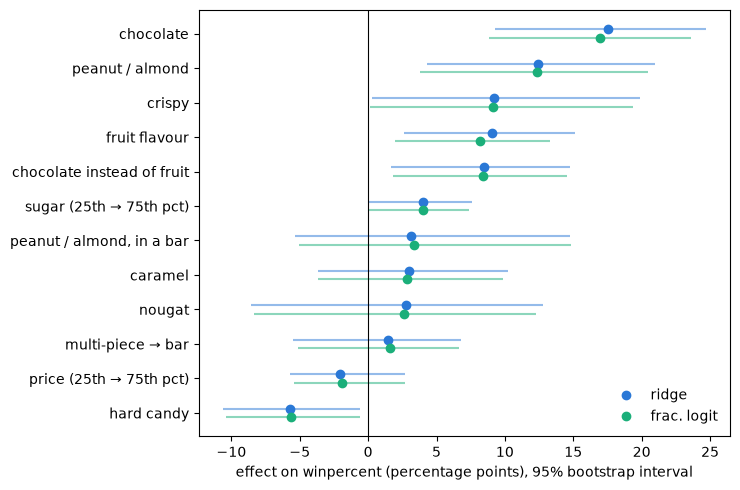

In [38]:
colors = {'ridge': '#2a78d6', 'frac. logit': '#1baf7a'}
e = eff.sort_values('ridge')
fig, ax = plt.subplots(figsize=(7.5, 5))
for k, (m, lo, hi) in enumerate([('ridge', 'ridge low', 'ridge high'), ('frac. logit', 'logit low', 'logit high')]):
    yk = np.arange(len(e)) + .12 - .24 * k
    ax.hlines(yk, e[lo], e[hi], color=colors[m], alpha=.5)
    ax.plot(e[m], yk, 'o', color=colors[m], label=m)
ax.axvline(0, color='black', lw=.8)
ax.set_yticks(range(len(e)), e.index)
ax.set_xlabel('effect on winpercent (percentage points), 95% bootstrap interval')
ax.legend(frameon=False, loc='lower right')
plt.tight_layout()
plt.savefig('outputs/fig1_drivers.png', dpi=200)

Chocolate is the largest effect in both models, and ridge and the logit agree on every characteristic to within about one point.

## 7. Which recipe scores best?

First, what each model would pick if any combination of characteristics were allowed:

In [39]:
grid = pd.DataFrame([list(c) + [recipes.sugarpercent.iloc[0], recipes.pricepercent.iloc[0], f]
                     for c in product([0, 1], repeat=7) for f in (-1, 0, 1)], columns=features)
G = grid.to_numpy()
pd.DataFrame({m: {'best recipe': recipe_name(grid.iloc[p(G).argmax()]), 'prediction': p(G).max(),
                  'products with it': (recipes.index == recipe_name(grid.iloc[p(G).argmax()])).sum()}
              for m, p in models.items()}).T

,best recipe,prediction,products with it
ridge,"chocolate, fruit flavour, caramel, peanut / almond, nougat, crispy",93.95,0
frac. logit,"chocolate, fruit flavour, caramel, peanut / almond, nougat, crispy",85.53,0


Both models simply switch on every characteristic with a positive coefficient and land on a candy with chocolate, fruit flavour, caramel, peanut and more (94% and 86%). No product like it exists, so this is extrapolation, not a forecast. I therefore only score the 28 recipes that real products have.

In [40]:
k0 = n_eff + len(concepts)
draws = boot['ridge'][:, k0:]
ranked = recipes[['n', 'mean']].assign(**{m: p(R) for m, p in models.items()})
ranked['P(best), ridge'] = np.bincount(draws.argmax(axis=1), minlength=len(R)) / len(draws)
ranked['vs A low'], ranked['vs A high'] = np.percentile(draws - boot['ridge'][:, [n_eff]], [2.5, 97.5], axis=0)
ranked = ranked.sort_values('ridge', ascending=False).round(2)
ranked.head(10)

,n,mean,ridge,frac. logit,"P(best), ridge",vs A low,vs A high
"chocolate, caramel, peanut / almond, crispy · bar",1,59.53,71.54,70.91,0.46,-5.42,20.96
"chocolate, peanut / almond",3,79.64,69.96,69.36,0.29,-9.61,16.80
"chocolate, caramel, crispy · bar",2,74.31,68.37,67.96,0.06,-3.64,10.23
"chocolate, peanut / almond · multi-piece",3,71.46,68.18,67.80,0.07,-10.37,16.58
"chocolate, crispy · bar",3,68.51,65.41,65.35,0.02,-0.00,0.00
"chocolate, caramel, peanut / almond, nougat · bar",2,66.79,65.11,64.96,0.04,-15.87,13.91
"chocolate, caramel, nougat · bar",2,66.95,61.94,61.75,0.02,-19.35,8.83
"chocolate, crispy · multi-piece",1,49.52,61.85,62.00,0.02,-8.88,3.76
"chocolate, peanut / almond · bar",3,58.54,59.37,59.65,0.00,-18.73,7.95
"chocolate, caramel · bar",1,64.35,59.16,59.15,0.00,-19.75,5.67


Both models rank the recipes in the same order, but no recipe wins clearly: even the most frequent winner in the ridge bootstrap is best in fewer than half of the resamples. The top two rest on weak evidence. The first is a single product, Snickers Crisper, which really scores only 59.5. The chocolate-peanut cup averages 79.6, but all three products are Reese's, so the brand is part of that number. Third comes chocolate + caramel + crispy bar (Twix, 100 Grand). Without the caramel (A: chocolate + crispy bar) the recipe is 5th; the caramel adds 3.0 points in ridge (interval −3.6 to +10.2), which is not demonstrated.

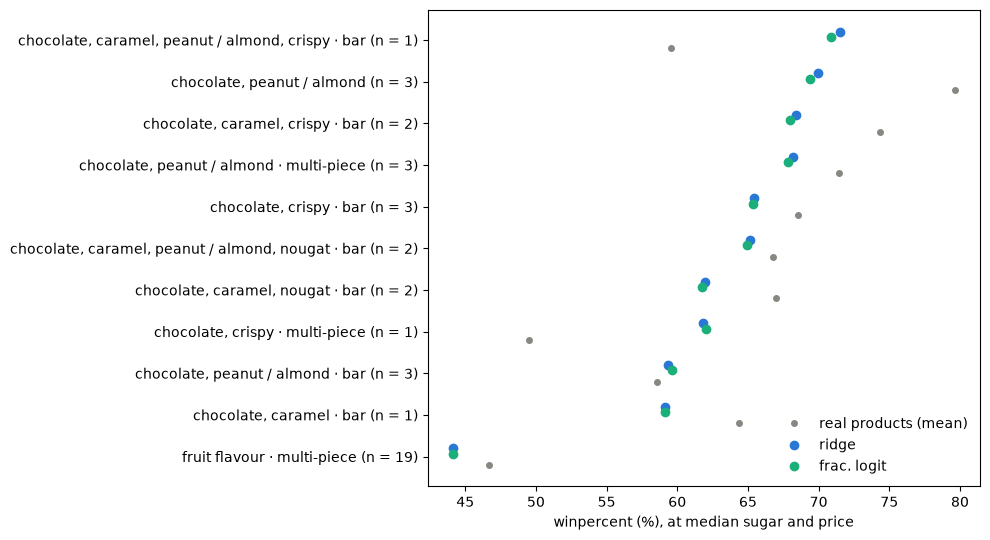

In [41]:
show = pd.concat([ranked.head(10), ranked.loc[[recipe_name(concepts.iloc[2])]]])
yy = np.arange(len(show))[::-1]
fig, ax = plt.subplots(figsize=(10, 5.5))
ax.plot(show['mean'], yy - .2, 'o', color='#898781', ms=4, label='real products (mean)')
for k, m in enumerate(models):
    ax.plot(show[m], yy + .2 - .13 * k, 'o', color=colors[m], label=m)
ax.set_yticks(yy, [f'{r} (n = {n})' for r, n in zip(show.index, show.n)])
ax.set_xlabel('winpercent (%), at median sugar and price')
ax.legend(frameon=False, loc='lower right')
plt.tight_layout()
plt.savefig('outputs/fig3_recipes.png', dpi=200)

The top of the list is chocolate throughout, mostly bars, and the crispy chocolate bar with and without caramel sits near the top. The gummy proxy ranks 21st of 28.

The three concepts in detail: A, the simplest recipe near the top; B, a peanut alternative; C, the gummy proxy.

In [42]:
scores =pd.DataFrame({m: p(concepts.to_numpy()) for m, p in models.items()}, index=concepts.index)
scores

,ridge,frac. logit
A: chocolate crispy bar,65.41,65.35
B: chocolate peanut bar,59.37,59.65
C: fruit multi-piece,44.16,44.12


Both models put the crispy bar at 65, the peanut bar at 59 to 60 and the fruit multi-piece candy at 44.

In [43]:
pairs = {'A − C': (0, 2), 'B − C': (1, 2), 'A − B': (0, 1)}
diffs = pd.DataFrame({m: [scores[m].iloc[a] - scores[m].iloc[b] for a, b in pairs.values()] for m in models}, index=list(pairs))
for m, short in [('ridge', 'ridge'), ('frac. logit', 'logit')]:
    d = np.array([boot[m][:, n_eff + a] - boot[m][:, n_eff + b] for a, b in pairs.values()])
    diffs[f'{short} low'], diffs[f'{short} high'] = np.percentile(d, [2.5, 97.5], axis=1)
diffs

,ridge,frac. logit,ridge low,ridge high,logit low,logit high
A − C,21.26,21.23,8.16,31.06,8.36,30.42
B − C,15.21,15.53,2.90,26.94,3.66,26.82
A − B,6.05,5.70,-7.95,18.73,-8.10,18.08


The crispy bar beats the gummy proxy by 21.3 points in ridge (95% interval 8.2 to 31.1) and 21.2 in the logit. Both models also put it ahead of the peanut bar, by 5.7 to 6.0 points, though that interval (−7.9 to +18.7 in ridge) still includes 0.

For comparison, ridge without the peanut × bar term:

In [44]:
pd.Series(ridge_no_interaction(X, y, tune(ridge_no_interaction, X, y, SEED))(concepts.to_numpy()), index=concepts.index)

A: chocolate crispy bar    64.76
B: chocolate peanut bar    65.77
C: fruit multi-piece       44.37
dtype: float64

Without the term, ridge gives the peanut bar 65.8 and ranks it one point above the crispy bar: it carries the peanut effect of Reese's cups over to a bar. With the term, ridge agrees with the real bars below.

Check against real products that have exactly the concept's characteristics:

In [45]:
same = {c: df[(df[features[:7] + ['form']] == concepts.loc[c, features[:7] + ['form']]).all(axis=1)] for c in concepts.index}
analogs = pd.DataFrame({c: {'n': len(g), 'mean winpercent': g.winpercent.mean(), 'products': ', '.join(g.competitorname)}
                        for c, g in same.items()}).T
analogs

,n,mean winpercent,products
A: chocolate crispy bar,3,68.51,"Hershey's Krackel, Kit Kat, Nestle Crunch"
B: chocolate peanut bar,3,58.54,"Almond Joy, Mr Good Bar, Nestle Butterfinger"
C: fruit multi-piece,19,46.66,"Chewey Lemonhead Fruit Mix, Chiclets, Dots, Fruit Chews, Haribo Gold Bears, Haribo Sou..."


The three crispy chocolate bars average 68.5, the three peanut bars 58.5 and the 19 fruit multi-piece candies 46.7: the same order as both models. With three products each, this is a check, not proof.

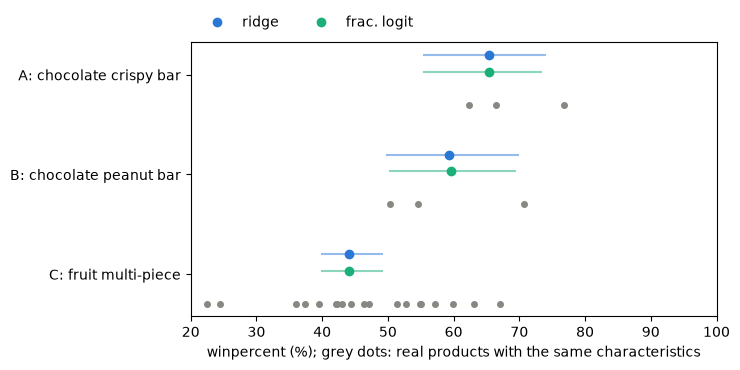

In [46]:
fig, ax = plt.subplots(figsize=(7.5, 3.8))
for i, c in enumerate(concepts.index):
    yb = 2 - i
    ax.plot(same[c].winpercent, np.full(len(same[c]), yb - .3), 'o', color='#898781', ms=4)
    for k, m in enumerate(models):
        yk = yb + .2 - .17 * k
        if m in boot:
            ax.hlines(yk, *np.percentile(boot[m][:, n_eff + i], [2.5, 97.5]), color=colors[m], alpha=.5)
        ax.plot(scores[m].iloc[i], yk, 'o', color=colors[m], label=m if i == 0 else None)
ax.set_yticks([2, 1, 0], concepts.index)
ax.set_xlim(20, 100)
ax.set_xlabel('winpercent (%); grey dots: real products with the same characteristics')
ax.legend(frameon=False, ncol=3, loc='lower left', bbox_to_anchor=(0, 1))
plt.tight_layout()
plt.savefig('outputs/fig2_concepts.png', dpi=200)

For every concept the model predictions (coloured) sit inside the spread of the real products (grey).

Where does the A − C gap come from? Going from C to A takes three changes. Each change is added in all 6 possible orders,
and its average contribution is kept (a Shapley decomposition with C as the reference), so the parts add up to the gap.

In [47]:
steps = {'fruit → chocolate': {'chocolate': 1, 'fruity': 0},
         'multi-piece → bar': {'form': 1},
         'crispy layer': {'crispedricewafer': 1}}

In [48]:
shapley = pd.DataFrame(0.0, index=list(steps), columns=list(models))
for m, predict in models.items():
    for order in permutations(steps):
        p = concepts.loc['C: fruit multi-piece'].copy()
        before = predict(p.to_numpy()[None])[0]
        for s in order:
            p.update(pd.Series(steps[s]))
            after = predict(p.to_numpy()[None])[0]
            shapley.loc[s, m] += (after - before) / 6
            before = after
shapley.loc['total (A − C)'] = shapley.sum()
shapley

,ridge,frac. logit
fruit → chocolate,8.48,8.39
multi-piece → bar,3.56,3.51
crispy layer,9.21,9.34
total (A − C),21.26,21.23


In both models the flavour switch and the bar format make up just over half of the gap (12.0 of 21.3 in ridge), and the crispy layer the rest (9.2). Some intermediate profiles, such as a crispy fruit candy, never occur in the data, so this shows how the models explain the gap, not measured effects.

One result is worth a second look. Shuffling the crispy flag barely changed ridge's test MAE (+0.25 points, section 5), yet the crispy layer accounts for 9.2 points of this gap. Only seven products carry the flag: a characteristic can matter for this particular recipe comparison while adding little to average accuracy across all 83 products.

A simple summary chart for the presentation (ridge scores):

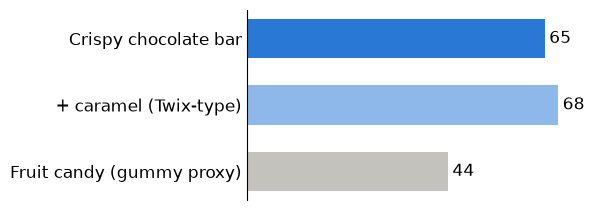

In [49]:
summary = pd.Series({'Fruit candy (gummy proxy)': scores.ridge.iloc[2],
                     '+ caramel (Twix-type)': ranked.loc['chocolate, caramel, crispy · bar', 'ridge'],
                     'Crispy chocolate bar': scores.ridge.iloc[0]})
fig, ax = plt.subplots(figsize=(6, 2.2))
ax.barh(summary.index, summary, color=['#c3c2bd', '#8fb8ea', '#2a78d6'], height=.6)
for i, v in enumerate(summary):
    ax.text(v + 1, i, f'{v:.0f}', va='center', fontsize=12)
ax.set_xticks([])
ax.spines[['top', 'right', 'bottom']].set_visible(False)
ax.tick_params(axis='y', length=0, labelsize=12)
plt.tight_layout()
plt.savefig('outputs/fig0_summary.png', dpi=200)

And the top recipes with example products (ridge scores):

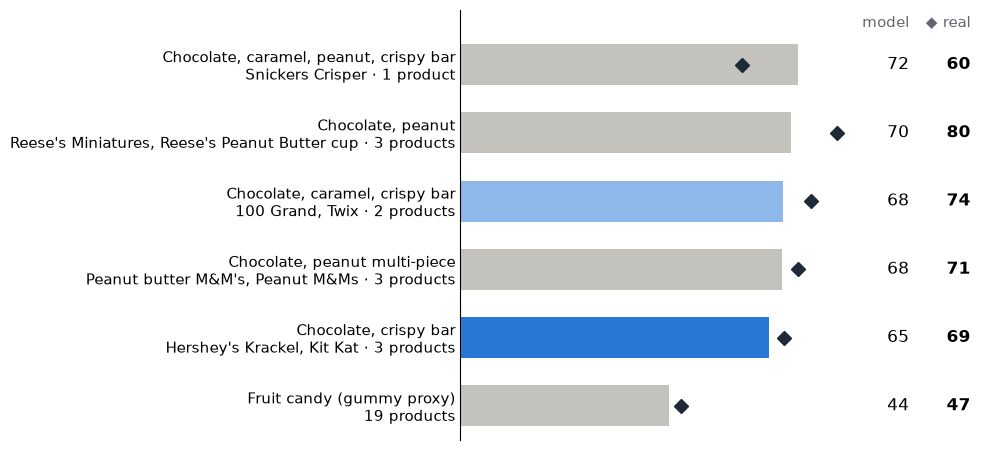

In [50]:
product_recipe = df.apply(recipe_name, axis=1)
top = pd.concat([ranked.head(5), ranked.loc[[recipe_name(concepts.iloc[2])]]])[::-1]
labels = [f"{r.replace('peanut / almond', 'peanut').replace(' · ', ' ').capitalize()}\n"
          f"{', '.join(df.competitorname[product_recipe == r].head(2))} · {n} product{'s' if n > 1 else ''}"
          for r, n in zip(top.index, top.n)]
labels[0] = f'Fruit candy (gummy proxy)\n{top.n.iloc[0]} products'
bar_colors = ['#2a78d6' if r == recipe_name(concepts.iloc[0]) else '#8fb8ea' if r == 'chocolate, caramel, crispy · bar'
              else '#c3c2bd' for r in top.index]
fig, ax = plt.subplots(figsize=(10, 4.6))
ax.barh(labels, top.ridge, color=bar_colors, height=.6)
ax.plot(top['mean'], range(len(top)), 'D', color='#1f2a37', ms=7)
for i, (p, r) in enumerate(zip(top.ridge, top['mean'])):
    ax.text(95, i, f'{p:.0f}', va='center', ha='right', fontsize=12)
    ax.text(108, i, f'{r:.0f}', va='center', ha='right', fontsize=12, weight='bold')
ax.text(95, len(top) - .45, 'model', ha='right', fontsize=10.5, color='#5f6670')
ax.text(108, len(top) - .45, '◆ real', ha='right', fontsize=10.5, color='#5f6670')
ax.set_xlim(0, 110)
ax.set_ylim(-.5, len(top) - .2)
ax.set_xticks([])
ax.spines[['top', 'right', 'bottom']].set_visible(False)
ax.tick_params(axis='y', length=0, labelsize=10.5)
plt.tight_layout()
plt.savefig('outputs/fig4_top_recipes.png', dpi=200)

## 8. Checks

Put the two coins back (85 rows) and recompute the ridge A − C gap:

In [51]:
d85 = raw.assign(form=raw.bar - raw.pluribus)
X85, y85 = d85[features].to_numpy(float), d85.winpercent.to_numpy()
p85 = ridge(X85, y85, tune(ridge, X85, y85, SEED))(concepts.to_numpy())
pd.Series({'83 candies': diffs.loc['A − C', 'ridge'], '85 rows (coins included)': p85[0] - p85[2]})

83 candies                  21.26
85 rows (coins included)    21.18
dtype: float64

With the coins the gap is 21.2 instead of 21.3, so excluding them does not drive the result.

How many shoppers does the proposed blind pairwise test need? Exact binomial test against 50 / 50, with 200 shoppers per pair:

In [52]:
n = 200
k_sig = next(k for k in range(n // 2, n + 1) if stats.binomtest(k, n).pvalue < .05)
test = pd.Series({'shoppers': n, 'wins needed for p < 0.05': k_sig, 'share needed': k_sig / n,
                  'p at 55% (110 wins)': stats.binomtest(110, n).pvalue, 'power if the true share is 60%': stats.binom.sf(k_sig - 1, n, .6)})
test

shoppers                          200.00
wins needed for p < 0.05          115.00
share needed                        0.57
p at 55% (110 wins)                 0.18
power if the true share is 60%      0.79
dtype: float64

With 200 shoppers per pair a 60 / 40 preference is detected with 79% power. A result is statistically clear only from 115 wins (57.5%); 55% alone gives p = 0.18, so a 55% business threshold has to be reported with its confidence interval.

Save the tables used in the presentation:

In [53]:
tables = {'groups': groups, 'crispy_products': crispy_products[['competitorname', 'winpercent', 'rank']],
          'accuracy': accuracy, 'comparison': comparison, 'effects': eff, 'concept_scores': scores,
          'concept_differences': diffs, 'analogs': analogs, 'recipes': ranked, 'shapley': shapley, 'importance': importance, 'shopper_test': test}
for name, table in tables.items():
    table.to_csv(f'outputs/{name}.csv')

## 9. Conclusions

**Which prototype.** A milk-chocolate bar with a crispy layer. Chocolate is the clearest driver: +18.7 points in the raw data, the largest effect in both models and by far the most important feature out of sample. Among the 28 recipes that real products have, the crispy chocolate bar ranks 5th, behind recipes that rest on a single product or a single brand, and just behind its caramel variant (Twix-type), whose +3 points are not demonstrated. It scores 21 points above the gummy proxy, and both models, like the real products, also rank it above a chocolate-peanut bar.

**Why the recipe is still uncertain.** Most of the gap to the gummy proxy is chocolate and the bar format. Only seven products carry the crispy flag, all of them with chocolate, so a plain biscuit cannot be scored. The lead over the peanut bar (about 6 points) is smaller than its uncertainty and rests on one interaction I added after seeing the data. The data are US online preferences for named brands, with several products per brand counted as independent, so the intervals are probably somewhat too narrow.

**What to test before launch.** Prototype the crispy bar with and without caramel. Blind-test the base bar against a leading branded bar with Lidl shoppers, then compare the two Lidl versions, and check shopper choice at the planned shelf price together with margin and allergens. About 200 shoppers per pair detect a 60 / 40 preference; a 55% result should be reported with its confidence interval.